# Dự báo lãi chiến lược bằng AI trên toàn bộ dữ liệu kế toán EW, so với EB (Chen & Dim)

**Bài toán.** Với mỗi chiến lược long–short và mỗi năm Y (1983–2020), dự báo lãi trung bình mỗi tháng của năm Y chỉ bằng dữ liệu trước Y. Chọn danh mục top 1/5/10% theo Sharpe dự báo (luật của paper) và so với EB.

**Dữ liệu.** Toàn bộ họ kế toán EW: 1.189.707 dòng (chiến lược, năm), 1966–2020, khoảng 26.000 chiến lược mỗi năm. EB được chấm lại trên đúng các dòng này.

**Cách học.** Học lại mỗi năm: để dự báo năm Y, học các dòng năm ≤ Y−2 (tối đa 500.000 dòng gần nhất), dùng năm Y−1 để chọn lúc dừng, rồi dự báo năm Y.

**Chọn cấu hình chỉ bằng dev (1983–2004); holdout (2005–2020) chỉ báo cáo.**

Notebook chỉ đọc các dự báo đã lưu (CPU). Mã huấn luyện: `code/run_full.py`, cấu hình: `code/full_cfgs.py`.

In [11]:
import os, sys, warnings
warnings.filterwarnings("ignore")
os.chdir("/home/phongndh/Documents/Paper/code"); sys.path.insert(0, ".")
import numpy as np, pandas as pd
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)
import report_full as r
from full_cfgs import FCFGS
print("dòng của bảng huấn luyện:", len(r.D.F), "| chiến lược:", r.D.F.signalid.nunique(), "| năm:", r.D.yr.min(), "-", r.D.yr.max())
print("dòng chấm điểm (1983-2020):", len(r.PC))

dòng của bảng huấn luyện: 1189707 | chiến lược: 29297 | năm: 1966 - 2020
dòng chấm điểm (1983-2020): 954643


## 1. Bảng huấn luyện: mỗi dòng là một chiến lược trong một năm

Mỗi dòng gồm **input** (dấu vân tay FinCast nén PCA [4×16], t-stat×dấu, lãi TB×dấu) và **đáp án** (lãi thật của chính năm đó). Chiến lược có lãi quá khứ âm bị nhân dấu −1 (làm ngược). Một chiến lược xuất hiện nhiều lần (mỗi năm một dòng).

In [12]:
D, F, yr, sd, sg = r.D, r.D.F, r.D.yr, r.D.sd, r.D.sg
H = np.load(r.h.CACHE / "full_acct_pca16.npy", mmap_mode="r")
y = D.y_or / sd; ym = pd.Series(y).groupby(yr).transform("mean").values; tgt = y - ym

def rows(idx):
    out = []
    for k in idx:
        t = np.asarray(H[k]).astype(np.float32)
        out.append({"signalid": int(F.signalid.values[k]), "năm": int(yr[k]), "dấu": int(sg[k]), "số tháng": int(F.nobs.values[k]),
                    "t-stat×dấu": round(F.tstat.values[k] * sg[k], 2), "lãi TB×dấu": round(F.mean_is.values[k] * sg[k], 3), "dao động": round(sd[k], 2),
                    "vec1 (3 số đầu)": " ".join(f"{v:.1f}" for v in t[0, :3]), "vec2": " ".join(f"{v:.1f}" for v in t[1, :3]),
                    "vec3": " ".join(f"{v:.1f}" for v in t[2, :3]), "vec4": " ".join(f"{v:.1f}" for v in t[3, :3]),
                    "lãi thật×dấu": round(D.y_or[k], 2), "Sharpe": round(y[k], 3), "đáp án": round(tgt[k], 3)})
    return pd.DataFrame(out)

rng = np.random.default_rng(7); pick = []
for lo, hi, n in ((1966, 1982, 3), (1983, 1999, 5), (2000, 2010, 4), (2011, 2020, 4)):
    pick += list(rng.choice(np.where((yr >= lo) & (yr <= hi))[0], n, replace=False))
display(rows(sorted(pick, key=lambda k: (yr[k], F.signalid.values[k]))))
print("số dòng mỗi năm:", pd.Series(yr).value_counts().sort_index().loc[[1966, 1975, 1983, 1990, 2000, 2010, 2020]].to_dict())

số dòng mỗi năm: {1966: 7253, 1975: 14413, 1983: 20477, 1990: 24228, 2000: 25603, 2010: 26478, 2020: 26073}


,signalid,năm,dấu,số tháng,t-stat×dấu,lãi TB×dấu,dao động,vec1 (3 số đầu),vec2,vec3,vec4,lãi thật×dấu,Sharpe,đáp án
0,15319,1978,-1,216,3.81,0.488,1.88,-1.5 1.0 -0.4,-0.9 1.7 1.1,-0.7 2.3 0.8,-0.7 1.7 -0.4,0.42,0.225,0.100
1,8452,1979,-1,174,0.98,0.344,4.65,1.8 1.8 1.6,0.0 0.1 1.2,0.7 0.4 0.9,1.5 0.7 -0.2,0.40,0.086,0.001
2,10364,1982,-1,240,4.83,0.651,2.09,-0.1 -0.8 -0.7,0.1 -0.9 0.8,-0.7 0.1 0.2,1.6 -1.1 -1.5,1.00,0.479,0.353
3,2570,1984,-1,150,0.89,0.123,1.70,0.9 -1.1 -0.5,0.8 0.0 -0.9,-1.5 0.9 -1.1,0.9 -0.2 0.3,0.29,0.170,0.216
4,11448,1987,-1,66,0.49,0.150,2.50,0.1 -0.4 -0.0,-0.8 -1.1 0.2,-1.4 -0.6 0.0,0.4 0.5 -1.8,0.20,0.082,-0.011
5,24194,1988,-1,210,0.60,0.098,2.38,0.6 -2.4 -2.5,-0.5 -1.7 -1.3,-1.9 -2.1 -1.3,0.4 -2.1 -0.2,-0.81,-0.338,-0.397
6,14514,1996,1,240,0.83,0.106,2.00,1.0 -0.4 0.7,0.6 0.8 0.3,3.2 0.4 -2.9,-1.7 -0.1 -0.0,0.25,0.127,0.048
7,10956,1997,-1,240,5.36,0.991,2.86,-0.1 0.9 -0.4,1.2 -0.6 2.0,-0.6 0.7 -0.4,-1.0 0.6 -0.2,0.79,0.277,0.193
8,13868,2001,1,240,0.93,0.126,2.10,-0.1 0.5 0.3,0.1 0.1 0.9,0.2 1.5 0.4,1.1 1.8 -0.1,-0.86,-0.409,-0.479
9,16178,2005,-1,240,0.96,0.281,4.55,-1.7 0.4 -0.5,0.8 -1.4 1.4,1.8 0.2 3.6,-0.7 0.4 -1.2,0.46,0.102,0.118


## 2. Nhãn học (đáp án gián tiếp)

Mô hình không đoán thẳng lãi gốc. Đáp án qua 4 bước (đều đảo ngược được, cuối cùng cộng lại để ra lãi dự báo):

1. nhân dấu: `lãi thật × dấu`
2. đơn vị Sharpe: chia cho độ dao động quá khứ
3. trừ trung bình Sharpe của cả năm (chỉ cần xếp hạng trong năm)
4. trừ **nền** = hệ số × z(|t-stat| trong năm), hệ số ước lượng bằng nhãn các năm Y−15…Y−1. Mạng chỉ học **phần dư**.

Cơ sở: Huber (1964) cho loss bền với đuôi dày; dự báo lãi chuẩn hóa theo độ dao động và xếp hạng theo Sharpe dự báo là luật của paper; học phần dư trên một nền đơn giản là dạng học residual (He et al. 2015). Bằng chứng thực nghiệm trong mục 5.

In [13]:
Y = 2000                                   # ví dụ: nhãn của các dòng học khi dự báo năm 2000
gk = yr
zf = lambda v: (v - pd.Series(v).groupby(gk).transform("mean").values) / (pd.Series(v).groupby(gk).transform("std").values + 1e-9)
Xb = zf(np.abs(F.tstat.values))[:, None]
fb = np.where((yr <= Y - 1) & (yr >= Y - 15) & np.isfinite(tgt))[0]
sb = Xb[fb].std(0) + 1e-9; A_ = Xb[fb] / sb; yb = np.clip(tgt[fb], *np.percentile(tgt[fb], [1, 99]))
wb = np.linalg.solve(A_.T @ A_ + np.eye(1), A_.T @ yb); base = ((Xb / sb) @ wb).ravel()
print("hệ số nền (ước lượng bằng các năm", Y - 15, "-", Y - 1, "):", wb.round(4))
ex = []
for sid, yy in ((18144, 1998), (2183, 1998), (18144, 1990)):
    k = np.where((F.signalid.values == sid) & (yr == yy))[0][0]
    ex.append({"signalid": sid, "năm": yy, "lãi thật gốc": round(F.mean_oos.values[k], 4), "× dấu": round(D.y_or[k], 4), "÷ dao động = Sharpe": round(y[k], 4),
               "− TB năm": round(ym[k], 4), "= ytar": round(tgt[k], 4), "− nền": round(base[k], 4), "= NHÃN học": round(tgt[k] - base[k], 4)})
pd.DataFrame(ex)

hệ số nền (ước lượng bằng các năm 1985 - 1999 ): [0.079]


,signalid,năm,lãi thật gốc,× dấu,÷ dao động = Sharpe,− TB năm,= ytar,− nền,= NHÃN học
0,18144,1998,-1.816,1.816,0.992,0.128,0.863,0.367,0.497
1,2183,1998,-0.862,0.862,0.500,0.128,0.371,0.146,0.225
2,18144,1990,-1.570,1.570,0.688,0.059,0.629,0.216,0.413


## 3. Chia theo năm (học lại mỗi năm)

Dự báo năm Y: **học** các dòng năm ≤ Y−2 (tối đa 500.000 dòng gần nhất), **validation** năm Y−1 (chọn lúc dừng, không cập nhật mô hình), **dự báo** năm Y. Mô hình năm sau bắt đầu từ trọng số năm trước. Dev = các dự báo 1983–2004; holdout = 2005–2020.

In [14]:
rows_ = []
for Yf in (1983, 1990, 2000, 2010, 2020):
    trn = np.where(yr <= Yf - 2)[0]; keep = trn[np.argsort(-yr[trn], kind="stable")[:500000]]
    rows_.append({"dự báo năm": Yf, "dòng học có sẵn": len(trn), "dòng học dùng": len(keep), "các năm học": f"{yr[keep].min()}-{yr[keep].max()}",
                  "validation (Y−1)": int((yr == Yf - 1).sum()), "dự báo (Y)": int((yr == Yf).sum())})
pd.DataFrame(rows_)

,dự báo năm,dòng học có sẵn,dòng học dùng,các năm học,validation (Y−1),dự báo (Y)
0,1983,214683,214683,1966-1981,20381,20477
1,1990,360488,360488,1966-1988,23123,24228
2,2000,613821,500000,1976-1998,25725,25603
3,2010,874872,500000,1989-2008,26432,26478
4,2020,1137594,500000,1999-2018,26040,26073


## 4. Mô hình và kỹ thuật, kèm nguồn

Khung (giữ từ notebook tham khảo B): FinCast (pretrained, đóng băng) → Bi-LSTM → attention → ghép [t-stat, lãi TB] → FC. Thêm: attention giữa các chiến lược cùng năm, nền theo |t-stat|, đáp án gián tiếp, 6 seed lấy trung bình, học lại mỗi năm.

| Kỹ thuật | Nguồn | Ghi chú |
|---|---|---|
| Luật xếp hạng, Table 2, Hình 4–5 | Chen & Dim, arXiv 2311.10685 (paper gốc) | EB chỉ là đối thủ, không dùng làm input |
| **HyperAttention** | Han et al., ICLR 2024 (bài của chủ dự án) | dùng cho attention giữa các chiến lược cùng năm (`xk=hyper`) |
| **Loss/Reward-Weighting** | Holen et al., arXiv 2304.12778 (bài của chủ dự án) | `lw`: gộp gradient K năm theo loss (đúng nguyên bản); `fyw=vH`: chuyển thể thành trọng số theo năm; đối chứng `lweq`: gộp trọng số đều |
| Set attention (ISAB) | Set Transformer, Lee et al. 2019 | **chưa xác minh được bài qua công cụ tìm bài** |
| Huber loss | Huber (1964), Ann. Math. Statist. 35(1), doi 10.1214/aoms/1177703732 | đã xác minh |
| ML dự báo lợi suất bằng neural nets | Gu, Kelly, Xiu (2020), RFS 33(5), doi 10.1093/rfs/hhaa009 | đã xác minh bài tồn tại; chi tiết trong bài chưa đọc |
| Ensemble nhiều seed | Dai, Liu, Zhu (2025), IEEE BigData, doi 10.1109/BigData66926.2025.11402413 | đã xác minh |
| Momentum chuỗi thời gian | Moskowitz, Ooi, Pedersen (2012), JFE 104(2), doi 10.1016/j.jfineco.2011.11.003 | đã xác minh |
| Pretrained | FinCast, Chronos-2, EXAONE Forecast for Finance (LG AI Research, arXiv 2609.04239) | **ghi rõ là pretrained**; bản không pretrained ở mục 8 |

Quy ước: R-weighted của Holen chỉ là thăm dò, không được chọn (nguyên tắc C của dự án).

## 5. Thang cải tiến từ baseline: dự đoán thẳng và dự đoán trung gian

`goc` = baseline kiểu notebook (đoán thẳng lãi, không attention giữa các chiến lược). Rồi thêm từng bước: attention giữa các chiến lược (`dir_isab`), đáp án đơn vị Sharpe trừ trung bình năm (`sh_isab_nobase`), nền theo |t-stat| (`Dt0_isab`). Cùng với HyperAttention: `dir_hyp`, `sh_hyp_nobase`, `Dt0_hyp`.

Cột: số seed, Sharpe trung bình của top 1/5/10% ở dev và holdout, IC trung bình theo năm.

In [15]:
ref = r.sharpe_table({"EB": D.eb_or, "|t| rule": r.abs_t_forecast()})
display(ref[["model", "dev top1/5/10", "dev mean", "holdout top1/5/10", "holdout mean", "IC dev", "IC hold"]])
ladder = ["goc", "dir_isab", "sh_isab_nobase", "Dt0_isab", "dir_hyp", "sh_hyp_nobase", "Dt0_hyp"]
lt = r.ensemble_table(ladder); display(lt)

,model,dev top1/5/10,dev mean,holdout top1/5/10,holdout mean,IC dev,IC hold
0,EB,1.55 / 1.91 / 1.86,1.774,0.82 / 0.78 / 0.86,0.817,0.188,0.021
1,|t| rule,1.95 / 1.99 / 1.85,1.931,0.84 / 0.75 / 0.83,0.808,0.064,0.023


,config,seeds,SR_dev,SR_hold,IC_dev,IC_hold
0,goc,3,1.243,0.555,0.048,0.029
1,dir_isab,3,1.365,0.686,0.135,0.055
2,sh_isab_nobase,3,1.842,0.813,0.157,0.045
3,Dt0_isab,6,1.865,0.921,0.157,0.053
4,dir_hyp,2,0.944,0.421,0.063,0.075
5,sh_hyp_nobase,2,1.599,0.896,0.107,0.059
6,Dt0_hyp,6,1.812,0.880,0.153,0.045


## 6. Các phương pháp từ bài và ý tưởng của chủ dự án

Một thay đổi mỗi lần so với bản nền ISAB (`Dt0_isab`) hoặc HyperAttention (`Dt0_hyp`):
- **HyperAttention** (Han et al., ICLR 2024): `Dt0_hyp`
- **Holen et al.** (arXiv 2304.12778): `I_vyH` (trọng số theo năm, chuyển thể), `I_lw4` (gộp gradient 4 năm theo loss, nguyên bản), `I_lweq4` (đối chứng: gộp 4 năm, trọng số đều), `Dt0_hyp_vyH` (HyperAttention + trọng số Holen)
- **Tăng dữ liệu** (ý tưởng của chủ dự án): `I_up2` (upsampling có nhiễu), `I_mix2` (mixup)
- **Đặc trưng tài chính** (35 đặc trưng): `Dt0_isab_F1`; **momentum**: `Dt0_hyp_E2`

In [16]:
ours = ["Dt0_isab", "Dt0_hyp", "I_vyH", "I_lw4", "I_lweq4", "Dt0_hyp_vyH", "I_up2", "I_mix2", "Dt0_isab_F1", "Dt0_hyp_E2"]
display(r.ensemble_table(ours))

,config,seeds,SR_dev,SR_hold,IC_dev,IC_hold
0,Dt0_isab,6,1.865,0.921,0.157,0.053
1,Dt0_hyp,6,1.812,0.880,0.153,0.045
2,I_vyH,6,1.924,0.900,0.159,0.035
3,I_lw4,6,1.876,0.849,0.136,0.038
4,I_lweq4,4,1.880,0.951,0.141,0.068
5,Dt0_hyp_vyH,1,1.803,0.835,0.140,0.032
6,I_up2,3,1.857,0.789,0.170,0.057
7,I_mix2,2,1.845,0.891,0.168,0.068
8,Dt0_isab_F1,3,1.472,0.843,0.166,0.059
9,Dt0_hyp_E2,3,1.466,0.892,0.137,0.076


## 7. Hàm loss, validation và học lại

- **Loss** (nền ISAB): Huber (`Dt0_isab`), MSE (`I_mse`), likelihood theo phương sai nhiễu (`I_nw`), thêm thành phần tương quan (`I_ctot`).
- **Validation:** 1 năm Y−1 (`Dt0_isab`, cách chính), 3 năm (`I_nv3`), không validation, học đến Y−1 (`I_nv0`).
- **Học lại mỗi năm** (`Dt0_isab`) so với **đóng băng sau 2004** (`I_freeze04`).

In [17]:
display(r.ensemble_table(["Dt0_isab", "I_mse", "I_nw", "I_ctot", "I_nv3", "I_nv0", "I_freeze04"]))

,config,seeds,SR_dev,SR_hold,IC_dev,IC_hold
0,Dt0_isab,6,1.865,0.921,0.157,0.053
1,I_mse,2,1.864,0.892,0.149,0.058
2,I_nw,2,1.867,0.909,0.154,0.072
3,I_ctot,2,1.788,0.824,0.143,0.076
4,I_nv3,2,1.877,0.885,0.153,0.062
5,I_nv0,2,1.429,0.573,0.098,0.018
6,I_freeze04,2,1.866,0.768,0.147,0.046


## 8. Encoder: pretrained và không pretrained

Pretrained: FinCast (`Dt0_isab`), Chronos-2 240 tháng (`I_chr2`), EXAONE Forecast for Finance (`I_ex`), gộp FinCast + EXAONE (`I_both`). **Không pretrained** (đối chứng bắt buộc): log-patch (`I_lp7`), raw (`I_raw`).

In [18]:
display(r.ensemble_table(["Dt0_isab", "I_chr2", "I_ex", "I_both", "I_lp7", "I_raw"]))

,config,seeds,SR_dev,SR_hold,IC_dev,IC_hold
0,Dt0_isab,6,1.865,0.921,0.157,0.053
1,I_chr2,2,1.837,0.827,0.168,0.081
2,I_ex,2,1.710,0.734,0.141,0.048
3,I_both,2,1.779,0.863,0.144,0.076
4,I_lp7,2,1.577,0.851,0.192,0.074
5,I_raw,2,1.766,0.531,0.129,0.084


## 9. Chọn cấu hình cuối (chỉ bằng dev) và so với EB

Quy tắc: trong các cấu hình đã chạy **ít nhất 4 seed**, chọn cấu hình có Sharpe dev trung bình (top 1/5/10%) cao nhất. Holdout chỉ báo cáo. Thử khoảng 40 cấu hình trên dữ liệu này (số lần thử chưa được hiệu chỉnh trong các p-value dưới đây).

In [19]:
cands = ["Dt0", "Dt0_hyp", "Dt0_hyp_hw3", "Dt0_hyp_nw", "Dt0_isab", "I_vyH", "I_lw4", "I_lweq4", "Dt0_hyp_vyH"]
sel_t = r.ensemble_table(cands); display(sel_t)
ok = sel_t[sel_t.seeds >= 4]
FINAL = ok.sort_values("SR_dev", ascending=False).iloc[0].config
print("cấu hình được chọn bằng dev (>= 4 seed):", FINAL, "| seeds", int(ok[ok.config == FINAL].seeds.iloc[0]))
p_final, n_final = r.mean_pred(FINAL); p_goc, _ = r.mean_pred("goc"); p_abs = r.abs_t_forecast()
R_fin, R_eb, R_goc, R_abs = r.portfolios(p_final), r.portfolios(D.eb_or.astype(np.float32)), r.portfolios(p_goc), r.portfolios(p_abs)
print("\n== Sharpe top 1/5/10% và IC"); display(r.sharpe_table({"FINAL": p_final, "EB": D.eb_or, "|t| rule": p_abs, "baseline goc": p_goc}, {"FINAL": R_fin, "EB": R_eb, "|t| rule": R_abs, "baseline goc": R_goc}))

cấu hình được chọn bằng dev (>= 4 seed): I_vyH | seeds 6

== Sharpe top 1/5/10% và IC


,config,seeds,SR_dev,SR_hold,IC_dev,IC_hold
0,Dt0,1,1.779,0.713,0.165,0.043
1,Dt0_hyp,6,1.812,0.880,0.153,0.045
2,Dt0_hyp_hw3,6,1.791,0.922,0.151,0.061
3,Dt0_hyp_nw,6,1.853,0.837,0.151,0.058
4,Dt0_isab,6,1.865,0.921,0.157,0.053
5,I_vyH,6,1.924,0.900,0.159,0.035
6,I_lw4,6,1.876,0.849,0.136,0.038
7,I_lweq4,5,1.881,0.922,0.143,0.051
8,Dt0_hyp_vyH,1,1.803,0.835,0.140,0.032


,model,dev top1/5/10,dev mean,holdout top1/5/10,holdout mean,full top1/5/10,full mean,IC dev,IC hold
0,FINAL,1.95 / 1.97 / 1.85,1.924,0.96 / 0.88 / 0.86,0.900,1.56 / 1.55 / 1.47,1.530,0.159,0.035
1,EB,1.55 / 1.91 / 1.86,1.774,0.82 / 0.78 / 0.86,0.817,1.27 / 1.48 / 1.48,1.409,0.188,0.021
2,|t| rule,1.95 / 1.99 / 1.85,1.931,0.84 / 0.75 / 0.83,0.808,1.52 / 1.51 / 1.47,1.499,0.064,0.023
3,baseline goc,1.34 / 1.23 / 1.16,1.243,0.61 / 0.51 / 0.54,0.555,1.07 / 0.97 / 0.94,0.994,0.048,0.029


In [20]:
print("== FINAL so với EB (HAC / bootstrap 10.000 lần / JKM cho chênh lệch Sharpe)"); display(r.compare(R_fin, R_eb, "FINAL", "EB"))
print("== FINAL so với quy tắc xếp theo |t-stat| (không mô hình)"); display(r.compare(R_fin, R_abs, "FINAL", "absT"))
print("== FINAL so với baseline kiểu notebook (goc)"); display(r.compare(R_fin, R_goc, "FINAL", "goc"))
ia, ie = r.ic_years(p_final), r.ic_years(D.eb_or)
print("== IC theo năm, FINAL − EB (Newey–West)"); display(pd.DataFrame({per: r.ic_test(ia, ie, lo, hi) for per, (lo, hi) in (("dev", (1983, 2004)), ("holdout", (2005, 2020)), ("full", (1983, 2020)))}).T.round(3))

== FINAL so với EB (HAC / bootstrap 10.000 lần / JKM cho chênh lệch Sharpe)
== FINAL so với quy tắc xếp theo |t-stat| (không mô hình)
== FINAL so với baseline kiểu notebook (goc)
== IC theo năm, FINAL − EB (Newey–West)


,top,period,SR FINAL,SR EB,p_HAC,p_boot,p_JKM,ret FINAL,ret EB
0,1%,dev,1.948,1.549,0.037,0.059,0.001,9.208,8.949
1,1%,holdout,0.963,0.818,0.261,0.256,0.291,2.972,2.791
2,1%,full,1.564,1.272,0.022,0.034,0.001,6.583,6.356
3,5%,dev,1.972,1.913,0.436,0.502,0.293,8.156,8.415
4,5%,holdout,0.875,0.778,0.318,0.327,0.344,2.284,2.292
5,5%,full,1.550,1.478,0.175,0.209,0.138,5.684,5.837
6,10%,dev,1.852,1.862,0.815,0.831,0.803,7.245,7.730
7,10%,holdout,0.863,0.855,0.930,0.934,0.928,2.010,2.258
8,10%,full,1.475,1.477,0.959,0.962,0.958,5.041,5.426


,top,period,SR FINAL,SR absT,p_HAC,p_boot,p_JKM,ret FINAL,ret absT
0,1%,dev,1.948,1.948,0.998,0.998,0.998,9.208,9.860
1,1%,holdout,0.963,0.839,0.299,0.242,0.361,2.972,2.915
2,1%,full,1.564,1.519,0.403,0.371,0.403,6.583,6.936
3,5%,dev,1.972,1.991,0.708,0.760,0.646,8.156,8.834
4,5%,holdout,0.875,0.749,0.196,0.176,0.227,2.284,2.220
5,5%,full,1.550,1.515,0.428,0.461,0.404,5.684,6.049
6,10%,dev,1.852,1.854,0.961,0.966,0.954,7.245,7.760
7,10%,holdout,0.863,0.834,0.745,0.757,0.746,2.010,2.212
8,10%,full,1.475,1.465,0.796,0.817,0.787,5.041,5.424


,top,period,SR FINAL,SR goc,p_HAC,p_boot,p_JKM,ret FINAL,ret goc
0,1%,dev,1.948,1.341,0.005,0.005,0.000,9.208,4.448
1,1%,holdout,0.963,0.613,0.167,0.187,0.125,2.972,1.398
2,1%,full,1.564,1.071,0.001,0.001,0.000,6.583,3.164
3,5%,dev,1.972,1.230,0.000,0.000,0.000,8.156,3.894
4,5%,holdout,0.875,0.513,0.058,0.100,0.038,2.284,1.011
5,5%,full,1.550,0.973,0.000,0.000,0.000,5.684,2.681
6,10%,dev,1.852,1.158,0.000,0.000,0.000,7.245,3.665
7,10%,holdout,0.863,0.539,0.059,0.130,0.034,2.010,0.914
8,10%,full,1.475,0.937,0.000,0.000,0.000,5.041,2.507


,IC_AI,IC_EB,diff,t,p,years_AI_better
dev,0.159,0.188,-0.028,-2.52,0.012,8/22
holdout,0.035,0.021,0.013,0.4,0.689,10/16
full,0.107,0.118,-0.011,-0.661,0.509,18/38


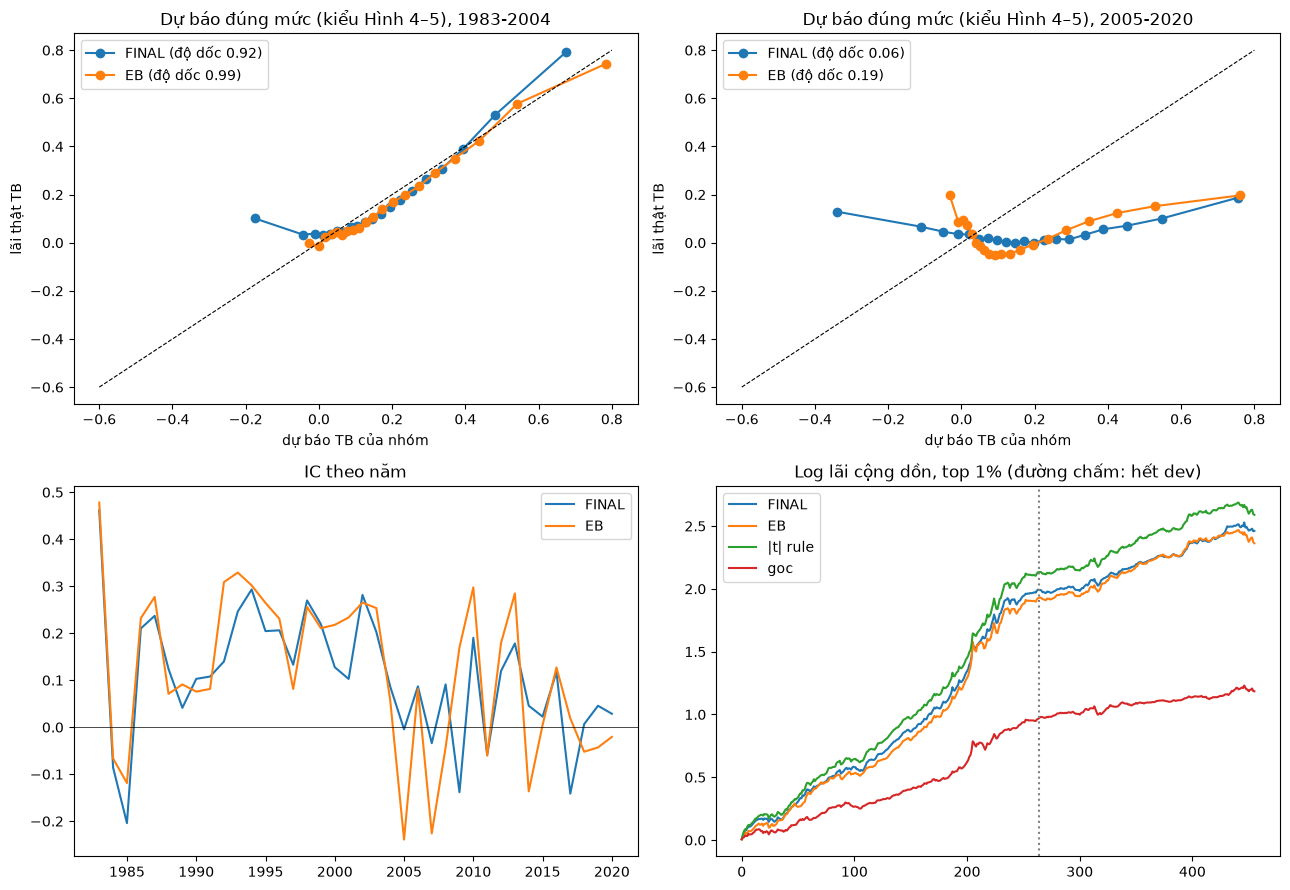

In [21]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
for j, (nm, lo, hi) in enumerate((("1983-2004", 1983, 2004), ("2005-2020", 2005, 2020))):
    for lab, q in (("FINAL", p_final), ("EB", D.eb_or)):
        g = r.calib_bins(q, lo, hi); b = np.polyfit(g.f, g.y, 1)
        ax[0, j].plot(g.f, g.y, "o-", label=f"{lab} (độ dốc {b[0]:.2f})")
    ax[0, j].plot([-.6, .8], [-.6, .8], "k--", lw=.8); ax[0, j].set_title(f"Dự báo đúng mức (kiểu Hình 4–5), {nm}"); ax[0, j].set_xlabel("dự báo TB của nhóm"); ax[0, j].set_ylabel("lãi thật TB"); ax[0, j].legend()
ax[1, 0].plot(ia.index, ia.values, label="FINAL"); ax[1, 0].plot(ie.index, ie.values, label="EB"); ax[1, 0].axhline(0, c="k", lw=.5); ax[1, 0].set_title("IC theo năm"); ax[1, 0].legend()
for lab, R_ in (("FINAL", R_fin), ("EB", R_eb), ("|t| rule", R_abs), ("goc", R_goc)):
    s = R_[(1, "eq")]; x = s.ret.values / 100; ax[1, 1].plot(np.cumsum(np.log1p(x)), label=lab)
ax[1, 1].axvline(264, c="gray", ls=":"); ax[1, 1].set_title("Log lãi cộng dồn, top 1% (đường chấm: hết dev)"); ax[1, 1].legend()
plt.tight_layout(); plt.show()

## 10. Kết luận và giới hạn

**Cấu hình cuối chọn bằng dev:** `I_vyH` = FinCast (pretrained) → Bi-LSTM → attention → **ISAB giữa các chiến lược cùng năm** → FC, đáp án gián tiếp (đơn vị Sharpe, trừ trung trình năm, trừ nền |t-stat|), loss Huber **có trọng số theo năm kiểu Holen et al.** (chuyển thể từ bài của chủ dự án), học lại mỗi năm (học đến Y−2, validation Y−1), 6 seed lấy trung bình.

**Kết quả (toàn bộ họ kế toán EW, ~26.000 chiến lược mỗi năm):**
- **Vượt baseline kiểu notebook B** ở mọi mục: Sharpe dev 1,95 / 1,97 / 1,85 so với 1,34 / 1,23 / 1,16 (p ≤ 0,005), holdout 0,96 / 0,88 / 0,86 so với 0,61 / 0,51 / 0,54.
- **Vượt EB ở top 1%:** dev 1,95 so với 1,55 (HAC p = 0,037, bootstrap p = 0,059, JKM p = 0,001); cả kỳ 1,56 so với 1,27 (HAC p = 0,022, bootstrap p = 0,034). Trung bình ba mức top-k cao hơn EB ở dev (1,92 so với 1,77) và holdout (0,90 so với 0,82).
- **Ngang EB** ở top 5% và 10%; holdout cao hơn EB ở top 1% và 5% nhưng **không có ý nghĩa thống kê** (p ≥ 0,26).
- **IC theo năm thấp hơn EB ở dev** (0,159 so với 0,188, p = 0,012); ngang ở holdout. Dự báo đúng mức: độ dốc dev 0,92 (EB 0,99), holdout 0,06 (EB 0,19).

**Giới hạn:**
- **Không hơn quy tắc xếp theo |t-stat|** (không mô hình): dev ngang (top 1% giống hệt 1,948); holdout cao hơn nhưng không có ý nghĩa. Phần mạng học thêm chưa chứng minh thêm thông tin ngoài |t-stat|.
- Đã thử khoảng 40 cấu hình trên dữ liệu này; p-value chưa hiệu chỉnh cho số lần thử.
- Mô hình dùng encoder **pretrained** (FinCast). Bản không pretrained (`I_lp7`, `I_raw`) kém hơn ở Sharpe (mục 8), dù `I_lp7` có IC dev cao nhất (0,192).
- Lợi ích của trọng số Holen so với bản ISAB thường (1,92 so với 1,87 ở dev) nằm trong mức nhiễu giữa các seed; đối chứng gộp gradient trọng số đều (`I_lweq4`) cho kết quả tương đương bản có trọng số loss của Holen, nên phần lợi ích có thể đến từ việc gộp nhiều năm trong mỗi bước cập nhật.
- Chưa chạy kiểm tra họ Ticker với mô hình toàn bộ dữ liệu.

**Điều rút ra về thiết kế:** đáp án gián tiếp (đơn vị Sharpe, trừ trung bình năm) là yếu tố quyết định (mục 5: từ 1,37 lên 1,84); năm Y−1 làm validation là cần thiết (không validation: 1,43); học lại mỗi năm giúp holdout (đóng băng sau 2004: 0,77 so với 0,92).